# MEDE U12 · CP2: matricea X, analiza univariata/bivariata, prima proiectie PCA
**Unitate:** statie × zi, Bucuresti, 2025 · **Surse:** calitateaer.ro (PM10, NO₂, orar) + Open-Meteo (T, precipitatii, vant, orar)

Intrare: `data/processed/hourly_aligned.csv` (rezultatul `01_load_align.ipynb`). Iesiri: `data/processed/` (matricea X, dictionarul de trasaturi, statistici, corelatii, incarcari PCA, raport QC) si `figures/`.
Rulare: *Restart & Run All*.

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, FIG = ROOT / "data" / "processed", ROOT / "figures"
FIG.mkdir(exist_ok=True)
MIN_HOURS = 18   # zi valida pentru un poluant: ≥ 18 din 24 de ore valide
CALM = 2.0       # prag de vant slab (m/s): ore cu vant < 2 m/s (stagnare)
plt.rcParams.update({"figure.dpi": 130, "font.size": 8})

## 1. Aliniere (recapitulare)
Unitatea e o **statie** (punct), deci nu exista grid comun sau interpolare spatiala: fiecare statie primeste meteo din celula Open-Meteo asociata coordonatelor ei. Pasul de timp e **ziua**, obtinuta prin agregare din datele orare. Golurile de poluanti se trateaza prin **excluderea** zilelor cu mai putin de 18 ore valide (fara imputare); meteo nu are goluri.

In [9]:
h = pd.read_csv(PROC / "hourly_aligned.csv", parse_dates=["time"]).set_index("time")
print(h.shape, h["station"].unique())
h.head(3)

(26274, 6) ['B-3' 'B-4' 'B-6']


,station,NO2,PM10,T,P,W
time,,,,,,
2025-01-01 00:00:00,B-3,43.30,122.06,-0.5,0.0,2.250000
2025-01-01 01:00:00,B-3,40.92,158.43,-0.4,0.0,2.444444
2025-01-01 02:00:00,B-3,36.27,72.46,-0.3,0.0,2.777778


### Control de calitate (QC) inainte de trasaturi
in datele orare de PM10 apar valori negative (zgomot al aparatului), doua varfuri izolate de sute de µg/m³ si doua zile cu 24 de valori identice (aparat blocat). Regula aplicata, fara a modifica fisierele din CP1: valorile in afara intervalului [0, 500] µg/m³ si zilele cu valoare constanta devin NaN. Numarul de ore afectate se raporteaza mai jos.

In [10]:
LIMITS = (0, 500)   # interval valid pentru PM10 si NO2 (µg/m³)
hq = h.copy()
hq["date"] = hq.index.normalize()
qc_rows = []
for p in ["NO2", "PM10"]:
    out_rng = (hq[p] < LIMITS[0]) | (hq[p] > LIMITS[1])
    flat = hq.groupby(["station", "date"])[p].transform(lambda s: s.nunique() == 1 and s.count() >= 12)
    for st in hq["station"].unique():
        m = hq["station"] == st
        qc_rows.append({"statie": st, "poluant": p,
                        "ore in afara [0, 500]": int(out_rng[m].sum()),
                        "ore din zile cu valoare constanta": int((flat & m & ~out_rng).sum())})
    hq.loc[out_rng | flat.astype(bool), p] = np.nan
qc = pd.DataFrame(qc_rows)
qc.to_csv(PROC / "qc_report.csv", index=False)
h = hq.drop(columns="date")
qc

,statie,poluant,"ore in afara [0, 500]",ore din zile cu valoare constanta
0,B-3,NO2,0,0
1,B-4,NO2,0,0
2,B-6,NO2,0,0
3,B-3,PM10,73,24
4,B-4,PM10,9,0
5,B-6,PM10,86,24


## 2. Trasaturi pe statie × zi, grupate pe sursa
Trei grupuri: **calitateaer.ro** (poluanti), **Open-Meteo** (meteo) si **calendar**. Fiecare trasatura e definita in dictionarul de mai jos (sursa, formula, unitate).

In [11]:
def station_features(d):
    d = d.copy()
    d["date"], d["hour"] = d.index.normalize(), d.index.hour
    g = d.groupby("date")
    out = pd.DataFrame(index=g.size().index)

    # --- grup A: calitateaer.ro (poluanti) ---
    for p in ["NO2", "PM10"]:
        ok = g[p].count() >= MIN_HOURS
        out[f"{p}_mean"] = g[p].mean().where(ok)
        out[f"{p}_max"] = g[p].max().where(ok)
        out[f"{p}_min"] = g[p].min().where(ok)
        out[f"{p}_std"] = g[p].std().where(ok)
        morn = d[d["hour"].between(6, 9)].groupby("date")[p]
        eve = d[d["hour"].between(17, 21)].groupby("date")[p]
        out[f"{p}_morning"] = morn.mean().where(morn.count() >= 3)
        out[f"{p}_evening"] = eve.mean().where(eve.count() >= 3)
    out["PM10_NO2_ratio"] = out["PM10_mean"] / out["NO2_mean"]
    out["NO2_lag1"] = out["NO2_mean"].shift(1)
    out["PM10_lag1"] = out["PM10_mean"].shift(1)

    # --- grup B: Open-Meteo (meteo) ---
    out["T_mean"], out["T_max"], out["T_min"] = g["T"].mean(), g["T"].max(), g["T"].min()
    out["T_range"] = out["T_max"] - out["T_min"]
    out["P_sum"] = g["P"].sum()
    out["P_hours"] = d.assign(r=d["P"] > 0.1).groupby("date")["r"].sum()
    out["P_sum_3d"] = out["P_sum"].rolling(3, min_periods=1).sum()
    out["W_mean"], out["W_max"] = g["W"].mean(), g["W"].max()
    out["W_calm_hours"] = d.assign(c=d["W"] < CALM).groupby("date")["c"].sum()

    # --- grup C: calendar ---
    out["is_weekend"] = (out.index.dayofweek >= 5).astype(int)
    return out

feats = pd.concat({s: station_features(g) for s, g in h.groupby("station")},
                  names=["station", "date"]).reset_index()
SEASON = {12: "iarna", 1: "iarna", 2: "iarna", 3: "primavara", 4: "primavara", 5: "primavara",
          6: "vara", 7: "vara", 8: "vara"}
feats["anotimp"] = feats["date"].dt.month.map(SEASON).fillna("toamna")
print("randuri inainte de eliminarea golurilor:", len(feats))

randuri inainte de eliminarea golurilor: 1095


In [12]:
GROUPS = {
 "calitateaer.ro (poluanti)": [c for c in feats.columns if c.startswith(("NO2", "PM10"))],
 "Open-Meteo (meteo)": [c for c in feats.columns if c.startswith(("T_", "P_", "W_"))],
 "calendar": ["is_weekend"],
}
FEATURES = [c for g in GROUPS.values() for c in g]
X = feats.dropna(subset=FEATURES).reset_index(drop=True)
print(f"n = {len(X)} randuri (statie × zi), d = {len(FEATURES)} trasaturi")
print("randuri pe statie:", X["station"].value_counts().sort_index().to_dict())
print("randuri pe anotimp:", X["anotimp"].value_counts().to_dict())

n = 1020 randuri (statie × zi), d = 26 trasaturi
randuri pe statie: {'B-3': 340, 'B-4': 342, 'B-6': 338}
randuri pe anotimp: {'toamna': 265, 'primavara': 261, 'iarna': 248, 'vara': 246}


### Dictionarul de trasaturi (provenienta)

In [13]:
SRC = {"NO2": "calitateaer.ro, NO₂ (42i), orar", "PM10": "calitateaer.ro, PM10 (Sharp 5030), orar",
       "T": "Open-Meteo, temperature_2m, orar", "P": "Open-Meteo, precipitation, orar",
       "W": "Open-Meteo, wind_speed_10m, orar (convertit in m/s)"}
POLL = {"mean": ("medie zilnica (≥ 18 ore valide)", "µg/m³"), "max": ("maxim zilnic", "µg/m³"),
        "min": ("minim zilnic", "µg/m³"), "std": ("abatere standard zilnica", "µg/m³"),
        "morning": ("medie orele 06–09 (≥ 3 ore valide)", "µg/m³"),
        "evening": ("medie orele 17–21 (≥ 3 ore valide)", "µg/m³"),
        "lag1": ("media zilnica din ziua precedenta", "µg/m³")}
MET = {"T_mean": ("medie zilnica", "°C"), "T_max": ("maxim zilnic", "°C"), "T_min": ("minim zilnic", "°C"),
       "T_range": ("T_max − T_min", "°C"), "P_sum": ("suma zilnica", "mm"),
       "P_hours": ("nr. de ore cu precipitatii > 0,1 mm", "ore"),
       "P_sum_3d": ("suma pe ziua curenta si 2 zile anterioare (primele 2 zile: suma partiala)", "mm"),
       "W_mean": ("medie zilnica", "m/s"), "W_max": ("maxim zilnic", "m/s"),
       "W_calm_hours": ("nr. de ore cu vant < 2 m/s", "ore")}
rows = []
for gname, cols in GROUPS.items():
    for c in cols:
        if c == "PM10_NO2_ratio":
            s, (d_, u) = "calitateaer.ro, derivata din PM10 si NO₂", ("PM10_mean / NO2_mean", "–")
        elif gname.startswith("calitateaer"):
            pol, _, suf = c.partition("_")
            s, (d_, u) = SRC[pol], POLL[suf]
        elif gname.startswith("Open"):
            s, (d_, u) = SRC[c.split("_")[0]], MET[c]
        else:
            s, d_, u = "calendar (data)", "1 daca ziua e sambata sau duminica", "0/1"
        rows.append({"trasatura": c, "grup": gname, "sursa": s, "definitie": d_, "unitate": u})
fdict = pd.DataFrame(rows)
fdict

,trasatura,grup,sursa,definitie,unitate
0,NO2_mean,calitateaer.ro (poluanti),"calitateaer.ro, NO₂ (42i), orar",medie zilnica (≥ 18 ore valide),µg/m³
1,NO2_max,calitateaer.ro (poluanti),"calitateaer.ro, NO₂ (42i), orar",maxim zilnic,µg/m³
2,NO2_min,calitateaer.ro (poluanti),"calitateaer.ro, NO₂ (42i), orar",minim zilnic,µg/m³
3,NO2_std,calitateaer.ro (poluanti),"calitateaer.ro, NO₂ (42i), orar",abatere standard zilnica,µg/m³
4,NO2_morning,calitateaer.ro (poluanti),"calitateaer.ro, NO₂ (42i), orar",medie orele 06–09 (≥ 3 ore valide),µg/m³
5,NO2_evening,calitateaer.ro (poluanti),"calitateaer.ro, NO₂ (42i), orar",medie orele 17–21 (≥ 3 ore valide),µg/m³
6,PM10_mean,calitateaer.ro (poluanti),"calitateaer.ro, PM10 (Sharp 5030), orar",medie zilnica (≥ 18 ore valide),µg/m³
7,PM10_max,calitateaer.ro (poluanti),"calitateaer.ro, PM10 (Sharp 5030), orar",maxim zilnic,µg/m³
8,PM10_min,calitateaer.ro (poluanti),"calitateaer.ro, PM10 (Sharp 5030), orar",minim zilnic,µg/m³
9,PM10_std,calitateaer.ro (poluanti),"calitateaer.ro, PM10 (Sharp 5030), orar",abatere standard zilnica,µg/m³


## 3. Analiza univariata
Statistici descriptive si distributii. Trasaturile cu asimetrie (skewness) > 1 sunt transformate cu `log1p` inainte de standardizare (regula fixata in prealabil, documentata in dictionar).

In [14]:
desc = X[FEATURES].describe().T
desc["skew"] = X[FEATURES].skew()
desc.round(2).to_csv(PROC / "descriptive_stats.csv")
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
NO2_mean,1020.0,34.32,14.04,10.36,23.90,32.21,42.28,134.14,1.32
NO2_max,1020.0,55.70,21.97,12.83,39.70,52.81,67.36,170.00,1.10
NO2_min,1020.0,18.83,8.82,6.17,12.46,16.92,23.18,95.18,1.94
NO2_std,1020.0,11.06,5.65,1.35,7.04,10.01,14.51,40.14,1.08
NO2_morning,1020.0,34.84,14.56,9.22,24.73,32.46,42.83,151.30,1.64
NO2_evening,1020.0,39.05,18.57,10.35,24.22,36.10,50.04,149.96,1.01
PM10_mean,1020.0,24.94,12.18,0.37,16.17,23.00,31.60,96.28,1.24
PM10_max,1020.0,47.50,27.22,2.44,29.74,41.90,57.43,238.29,1.86
PM10_min,1020.0,11.16,7.67,0.00,5.25,9.93,16.10,48.02,0.83
PM10_std,1020.0,10.09,7.05,0.65,5.49,8.44,12.04,54.79,2.25


In [15]:
BINARY = ["is_weekend"]
LOG_COLS = [c for c in FEATURES if c not in BINARY and desc.loc[c, "skew"] > 1]
assert (X[LOG_COLS].min() >= 0).all()
fdict["transformare"] = np.where(fdict["trasatura"].isin(LOG_COLS), "log1p, apoi z-score",
                                 np.where(fdict["trasatura"].isin(BINARY), "niciuna (binara)", "z-score"))
fdict.to_csv(PROC / "feature_dictionary.csv", index=False)
X.to_csv(PROC / "X_features.csv", index=False)
print("log1p aplicat la:", LOG_COLS)

log1p aplicat la: ['NO2_mean', 'NO2_max', 'NO2_min', 'NO2_std', 'NO2_morning', 'NO2_evening', 'PM10_mean', 'PM10_max', 'PM10_std', 'PM10_morning', 'PM10_evening', 'PM10_NO2_ratio', 'NO2_lag1', 'PM10_lag1', 'P_sum', 'P_hours', 'P_sum_3d', 'W_mean', 'W_max']


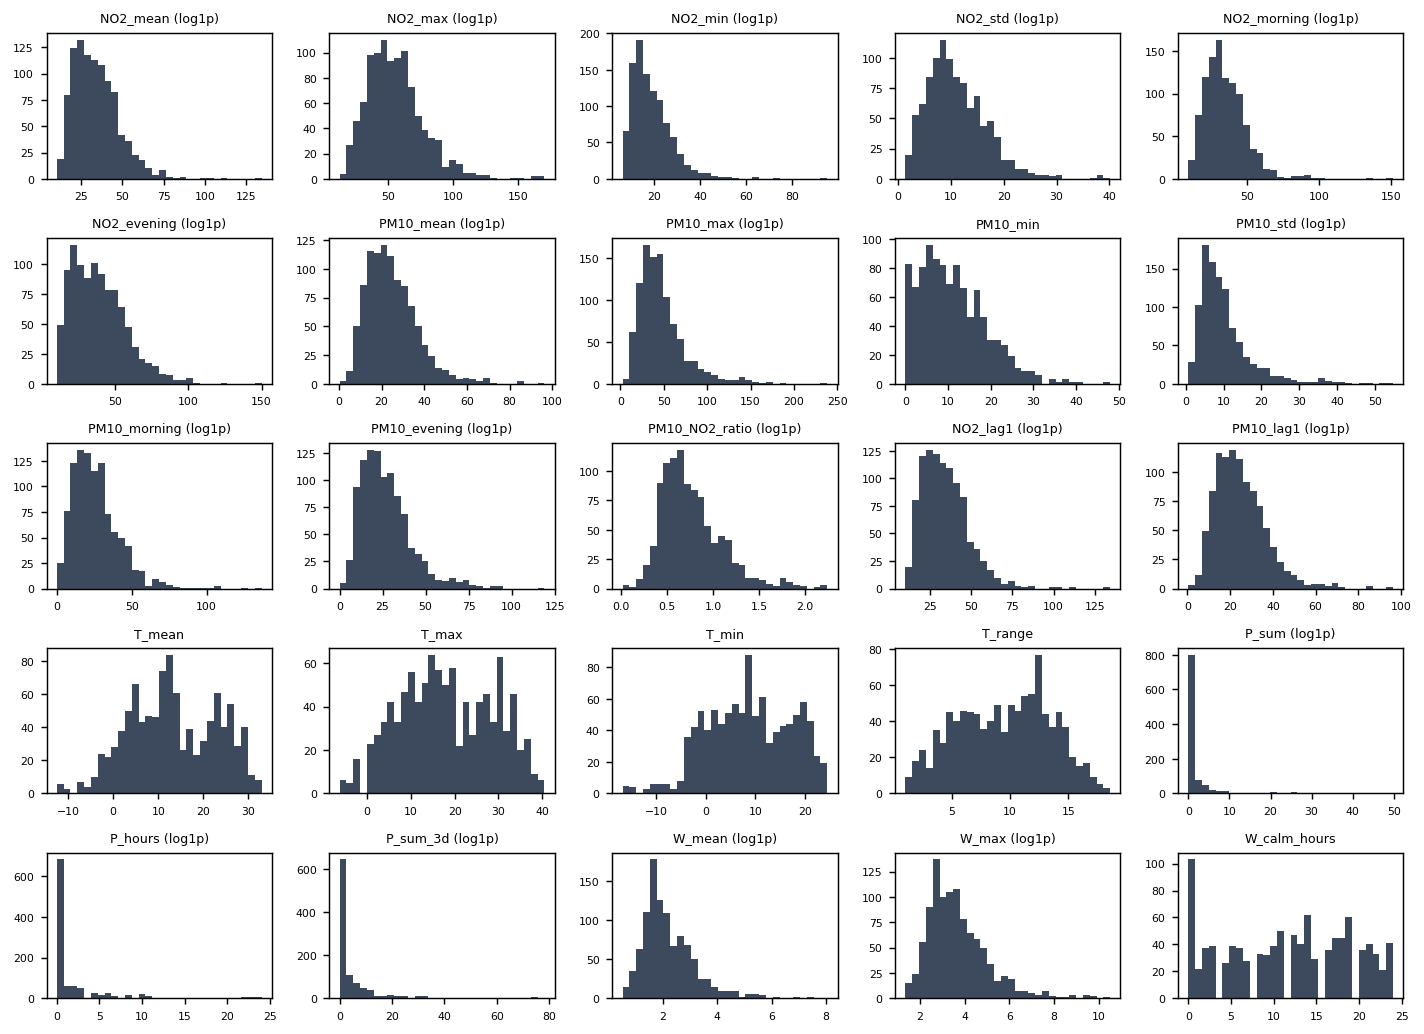

In [16]:
fig, axes = plt.subplots(5, 5, figsize=(11, 8))
for ax, c in zip(axes.ravel(), FEATURES):
    ax.hist(X[c], bins=30, color="#1B2A41", alpha=.85)
    ax.set_title(c + (" (log1p)" if c in LOG_COLS else ""), fontsize=7)
    ax.tick_params(labelsize=6)
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "distributions.png"); plt.show()

## 4. Analiza bivariata: corelatii
Matrice de corelatie Spearman (robusta la asimetrie), cu accent pe **corelatiile intre surse** (poluanti × meteo).

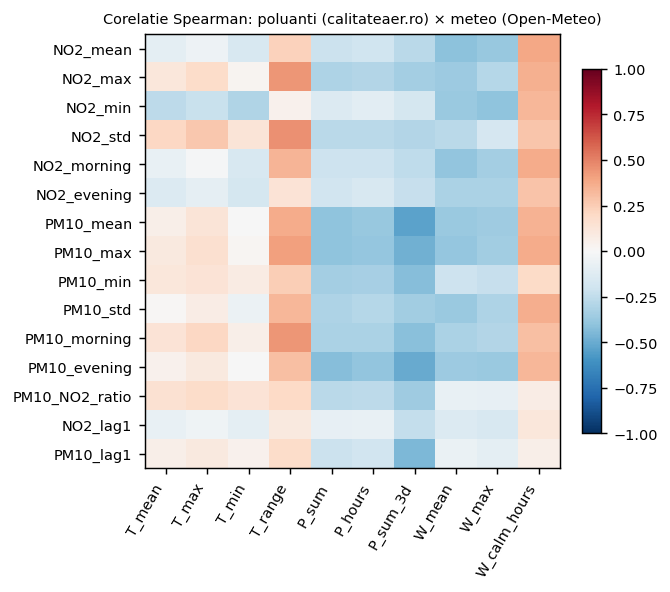

,,r,abs
PM10_mean,P_sum_3d,-0.53,0.53
PM10_evening,P_sum_3d,-0.50,0.50
PM10_max,P_sum_3d,-0.48,0.48
NO2_std,T_range,0.46,0.46
PM10_lag1,P_sum_3d,-0.45,0.45
NO2_max,T_range,0.44,0.44
PM10_morning,T_range,0.44,0.44
PM10_min,P_sum_3d,-0.43,0.43


In [17]:
corr = X[FEATURES].corr(method="spearman")
A, B = GROUPS["calitateaer.ro (poluanti)"], GROUPS["Open-Meteo (meteo)"]
cross = corr.loc[A, B]
cross.round(2).to_csv(PROC / "corr_cross_source.csv")

fig, ax = plt.subplots(figsize=(5.2, 4.6))
im = ax.imshow(cross.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(B))); ax.set_xticklabels(B, rotation=60, ha="right")
ax.set_yticks(range(len(A))); ax.set_yticklabels(A)
ax.set_title("Corelatie Spearman: poluanti (calitateaer.ro) × meteo (Open-Meteo)", fontsize=8)
plt.colorbar(im, ax=ax, fraction=.04); plt.tight_layout()
plt.savefig(FIG / "corr_cross_source.png"); plt.show()

top = cross.stack().rename("r").to_frame()
top["abs"] = top["r"].abs()
top.sort_values("abs", ascending=False).head(8).round(2)

## 5. Prima proiectie PCA
Scalare: `log1p` la trasaturile asimetrice, apoi standardizare (z-score). PCA pe trasaturi nescalate ar masura unitatile, nu structura. Scree plot-ul si incarcarile (loadings) sunt calculate pe toate randurile, ca analiza **exploratorie**.

In [18]:
def transform(df):
    Z = df[FEATURES].copy()
    Z[LOG_COLS] = np.log1p(Z[LOG_COLS])
    return Z

Zraw = transform(X)
scaler = StandardScaler().fit(Zraw)
Z = scaler.transform(Zraw)
pca = PCA().fit(Z)
ev = pca.explained_variance_ratio_
cum = ev.cumsum()
K = int(np.argmax(cum >= 0.80) + 1)          # prag de 80% varianta explicata
print("varianta explicata PC1–PC5:", ev[:5].round(3), "| cumulat:", cum[:5].round(3))
print(f"k ales: {K} (cumulat {cum[K-1]:.1%}; prag 80%, verificat pe cotul din scree plot)")

varianta explicata PC1–PC5: [0.365 0.162 0.104 0.084 0.06 ] | cumulat: [0.365 0.527 0.631 0.716 0.776]
k ales: 6 (cumulat 82.0%; prag 80%, verificat pe cotul din scree plot)


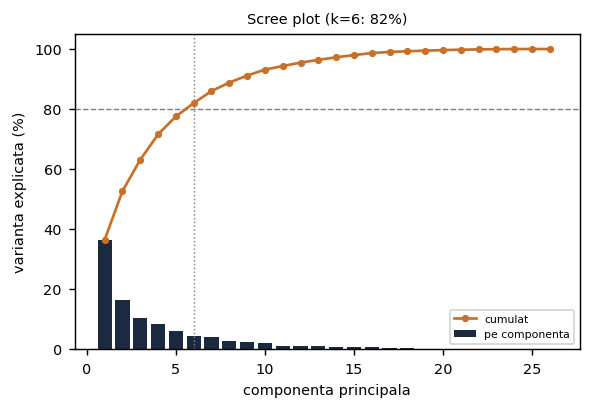

In [19]:
fig, ax = plt.subplots(figsize=(4.6, 3.2))
n = np.arange(1, len(ev) + 1)
ax.bar(n, ev * 100, color="#1B2A41", label="pe componenta")
ax.plot(n, cum * 100, "o-", color="#C8702A", ms=3, label="cumulat")
ax.axhline(80, color="gray", ls="--", lw=.8); ax.axvline(K, color="gray", ls=":", lw=.8)
ax.set_xlabel("componenta principala"); ax.set_ylabel("varianta explicata (%)")
ax.set_title(f"Scree plot (k={K}: {cum[K-1]:.0%})", fontsize=8); ax.legend(fontsize=6)
plt.tight_layout(); plt.savefig(FIG / "scree.png"); plt.show()

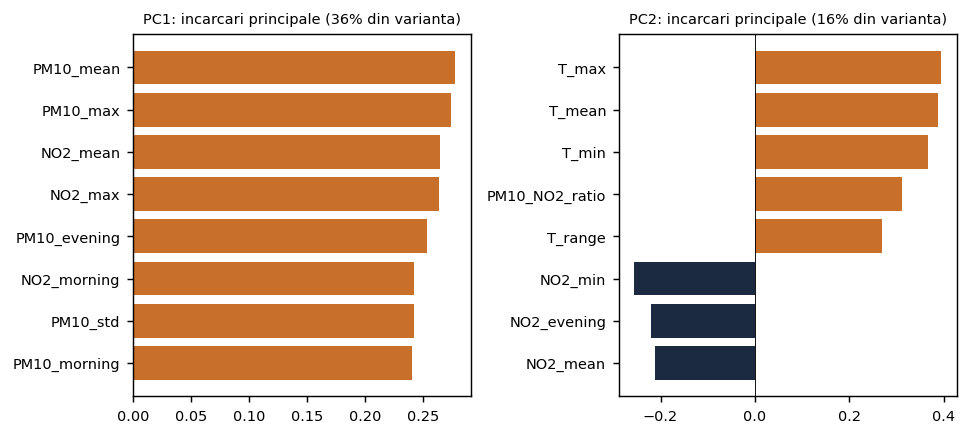

,PC1,PC2,PC3
0,PM10_mean,T_max,PM10_NO2_ratio
1,PM10_max,T_mean,T_mean
2,NO2_mean,T_min,T_min
3,NO2_max,PM10_NO2_ratio,T_max
4,PM10_evening,T_range,NO2_std


In [20]:
load = pd.DataFrame(pca.components_[:5].T, index=FEATURES, columns=[f"PC{i}" for i in range(1, 6)])
load.round(3).to_csv(PROC / "pca_loadings.csv")

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    s = load[pc].reindex(load[pc].abs().sort_values(ascending=False).index)[:8][::-1]
    ax.barh(s.index, s.values, color=["#C8702A" if v > 0 else "#1B2A41" for v in s.values])
    ax.set_title(f"{pc}: incarcari principale ({ev[int(pc[2:])-1]:.0%} din varianta)", fontsize=8)
    ax.axvline(0, color="k", lw=.5)
plt.tight_layout(); plt.savefig(FIG / "loadings.png"); plt.show()
load[["PC1", "PC2", "PC3"]].abs().apply(lambda c: c.sort_values(ascending=False).head(5).index.tolist())

## 6. Verificari

In [21]:
assert X[FEATURES].notna().all().all(), "NaN in matricea X"
assert len(FEATURES) == len(set(FEATURES)) == len(fdict)
assert np.allclose(Z.mean(axis=0), 0, atol=1e-8)
print(f"OK · n = {len(X)}, d = {len(FEATURES)}")

OK · n = 1020, d = 26
